In [ ]:
from google.colab import files

uploaded = files.upload()

Saving bigmart_Cleaned.csv to bigmart_Cleaned.csv


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("bigmart_Cleaned.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()

Dataset loaded successfully!
Shape: (8523, 13)


,Item_Identifier,Item_Weight,Item_Fat_Content,Item_Visibility,Item_Type,Item_MRP,Outlet_Identifier,Outlet_Establishment_Year,Outlet_Size,Outlet_Location_Type,Outlet_Type,Item_Outlet_Sales,Item_MRP_Band
0,FDA15,9.30,Low Fat,0.016047,Dairy,249.8092,OUT049,1999,Medium,Tier 1,Supermarket Type1,3735.1380,Very High Price
1,DRC01,5.92,Regular,0.019278,Soft Drinks,48.2692,OUT018,2009,Medium,Tier 3,Supermarket Type2,443.4228,Low Price
2,FDN15,17.50,Low Fat,0.016760,Meat,141.6180,OUT049,1999,Medium,Tier 1,Supermarket Type1,2097.2700,High Price
3,FDX07,19.20,Regular,0.054126,Fruits and Vegetables,182.0950,OUT010,1998,Unknown,Tier 3,Grocery Store,732.3800,High Price
4,NCD19,8.93,Low Fat,0.044997,Household,53.8614,OUT013,1987,High,Tier 3,Supermarket Type1,994.7052,Low Price


In [ ]:
sns.set_theme(style="whitegrid")

plt.rcParams["figure.figsize"] = (10, 6)

plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 11

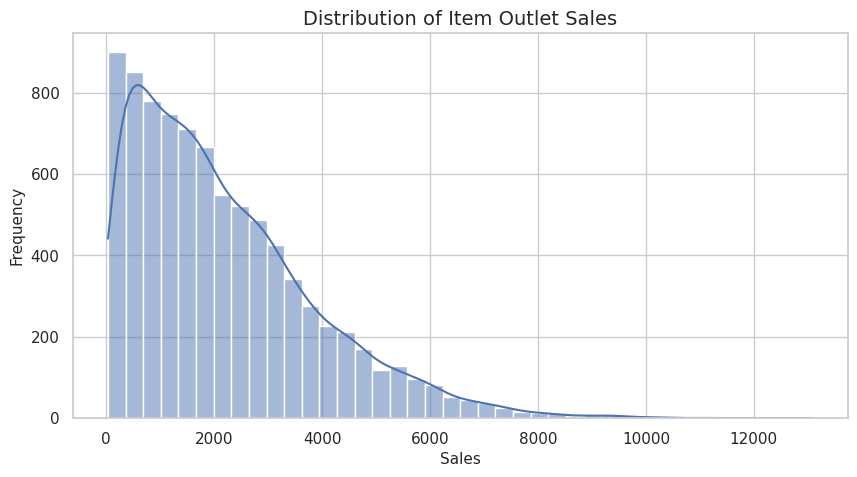

In [ ]:
plt.figure(figsize=(10, 5))

sns.histplot(
    df["Item_Outlet_Sales"],
    bins=40,
    kde=True
)

plt.title("Distribution of Item Outlet Sales")
plt.xlabel("Sales")
plt.ylabel("Frequency")

plt.show()

In [ ]:
df["Item_Outlet_Sales"].describe()

,Item_Outlet_Sales
count,8523.000000
mean,2181.288914
std,1706.499616
min,33.290000
25%,834.247400
50%,1794.331000
75%,3101.296400
max,13086.964800


In [ ]:
sales_by_category = (
    df.groupby("Item_Type", observed=True)["Item_Outlet_Sales"]
    .sum()
    .sort_values(ascending=False)
)

display(sales_by_category)

,Item_Outlet_Sales
Item_Type,
Fruits and Vegetables,2.820060e+06
Snack Foods,2.732786e+06
Household,2.055494e+06
Frozen Foods,1.825735e+06
Dairy,1.522594e+06
Canned,1.444151e+06
Baking Goods,1.265525e+06
Health and Hygiene,1.045200e+06
Meat,9.175656e+05


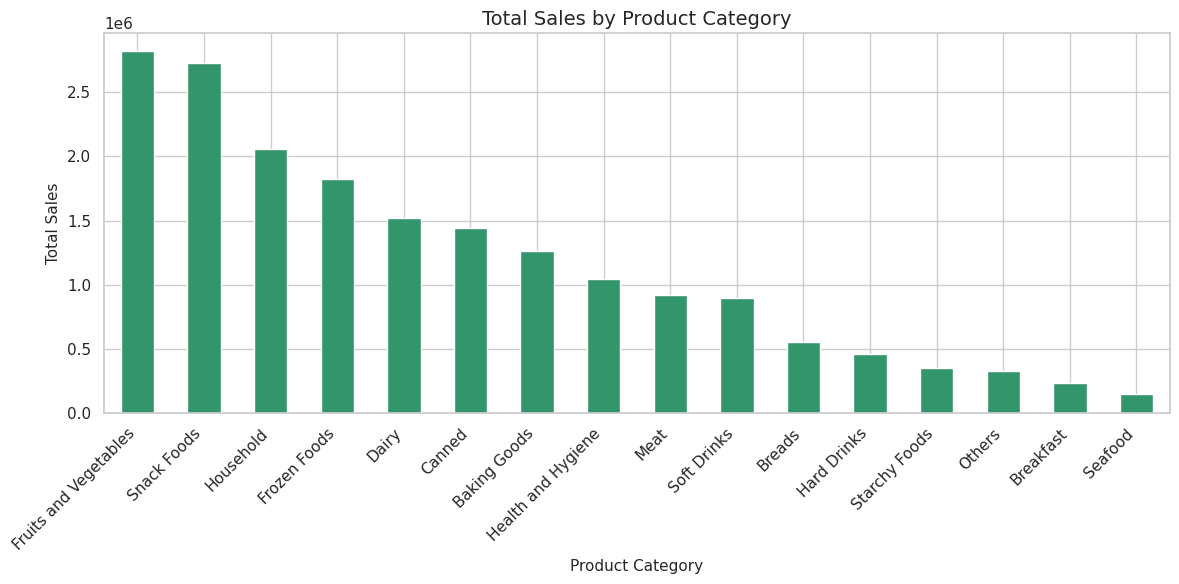

In [ ]:
plt.figure(figsize=(12, 6))

sales_by_category.plot(
    kind="bar",
    color="#32956B"
)

plt.title("Total Sales by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Sales")

plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

In [ ]:
sales_by_outlet = (
    df.groupby("Outlet_Type", observed=True)["Item_Outlet_Sales"]
    .sum()
    .sort_values(ascending=False)
)

display(sales_by_outlet)

,Item_Outlet_Sales
Outlet_Type,
Supermarket Type1,1.291734e+07
Supermarket Type3,3.453926e+06
Supermarket Type2,1.851823e+06
Grocery Store,3.680343e+05


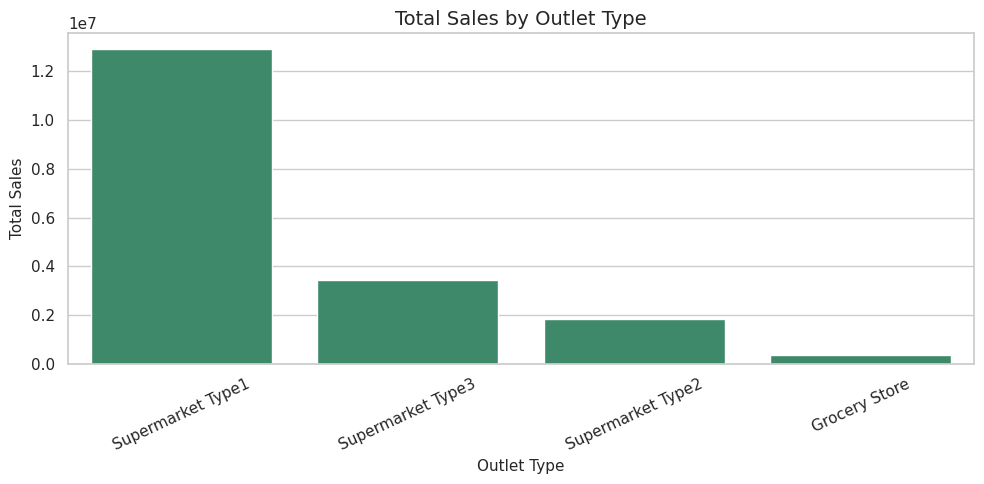

In [ ]:
plt.figure(figsize=(10, 5))

sns.barplot(
    x=sales_by_outlet.index,
    y=sales_by_outlet.values,
    color="#32956B"
)

plt.title("Total Sales by Outlet Type")
plt.xlabel("Outlet Type")
plt.ylabel("Total Sales")

plt.xticks(rotation=25)

plt.tight_layout()
plt.show()

In [ ]:
sales_by_location = (
    df.groupby(
        "Outlet_Location_Type",
        observed=True
    )["Item_Outlet_Sales"]
    .sum()
    .sort_values(ascending=False)
)

display(sales_by_location)

,Item_Outlet_Sales
Outlet_Location_Type,
Tier 3,7.636753e+06
Tier 2,6.472314e+06
Tier 1,4.482059e+06


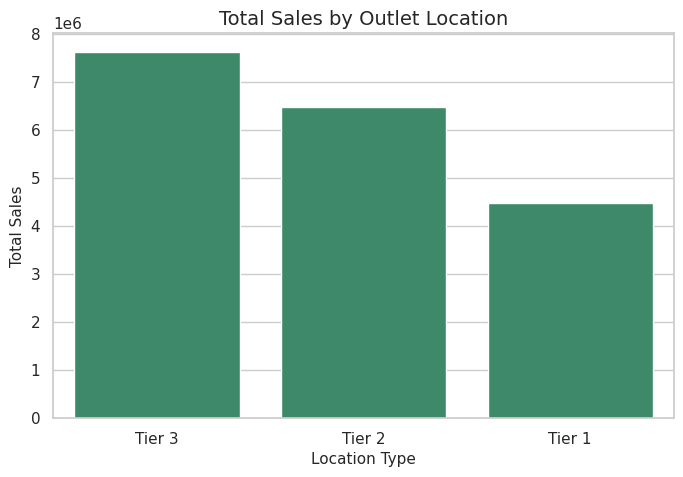

In [ ]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=sales_by_location.index,
    y=sales_by_location.values,
    color="#32956B"
)

plt.title("Total Sales by Outlet Location")
plt.xlabel("Location Type")
plt.ylabel("Total Sales")

plt.show()

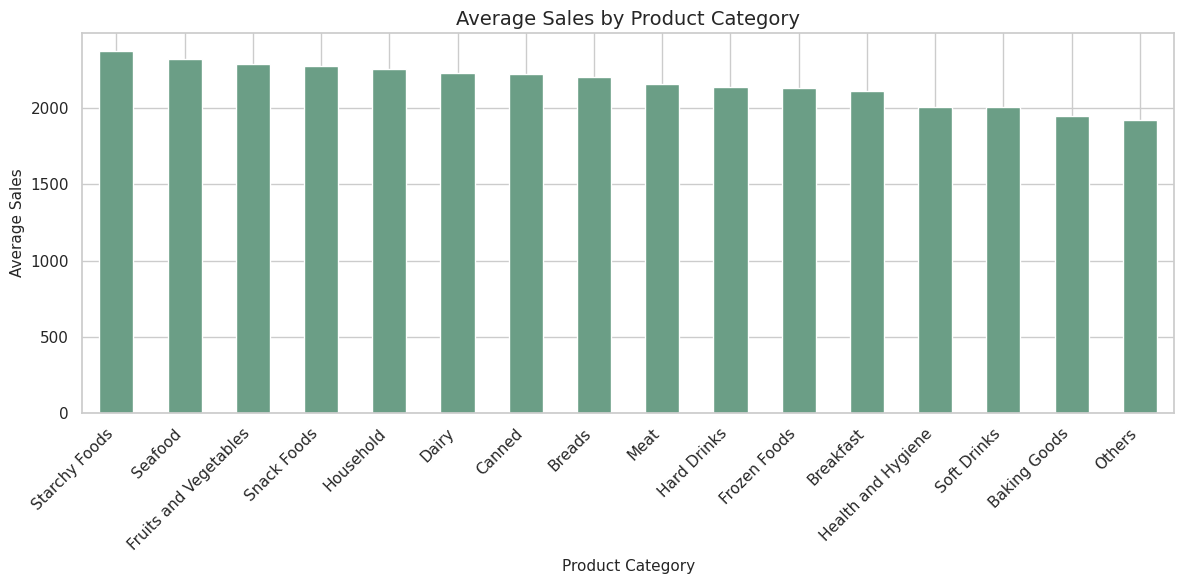

In [ ]:
average_sales = (
    df.groupby("Item_Type", observed=True)["Item_Outlet_Sales"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(12, 6))

average_sales.plot(
    kind="bar",
    color="#6B9E86"
)

plt.title("Average Sales by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Average Sales")

plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

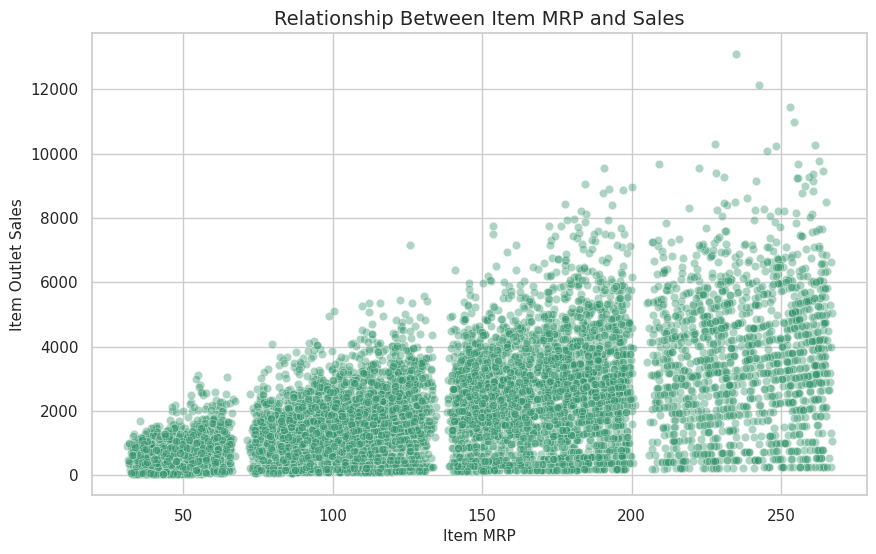

In [ ]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="Item_MRP",
    y="Item_Outlet_Sales",
    alpha=0.4,
    color="#32956B"
)

plt.title("Relationship Between Item MRP and Sales")
plt.xlabel("Item MRP")
plt.ylabel("Item Outlet Sales")

plt.show()

In [ ]:
correlation = df[
    ["Item_MRP", "Item_Outlet_Sales"]
].corr()

display(correlation)

,Item_MRP,Item_Outlet_Sales
Item_MRP,1.000000,0.567574
Item_Outlet_Sales,0.567574,1.000000


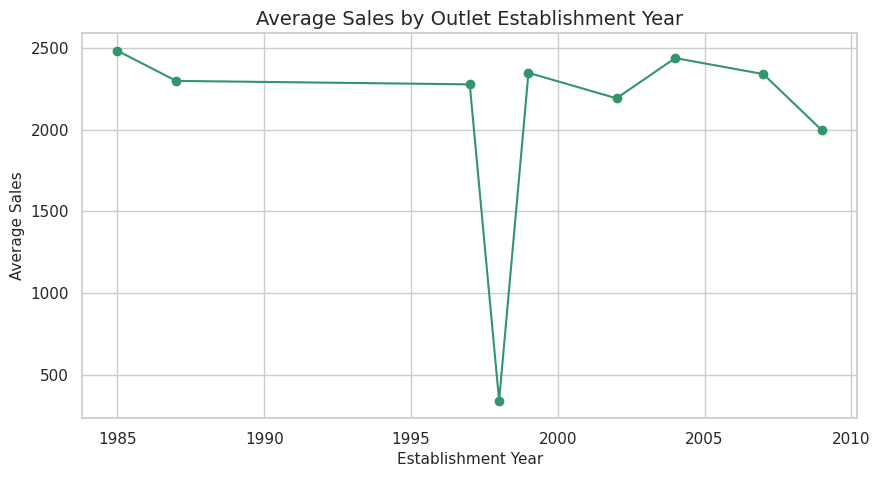

In [ ]:
sales_by_year = (
    df.groupby("Outlet_Establishment_Year")[
        "Item_Outlet_Sales"
    ].mean().sort_index()
)

plt.figure(figsize=(10, 5))

sales_by_year.plot(
    marker="o",
    color="#32956B"
)

plt.title("Average Sales by Outlet Establishment Year")
plt.xlabel("Establishment Year")
plt.ylabel("Average Sales")

plt.show()

# Machine Learning and Predictive Modeling

In [19]:
from sklearn.model_selection import train_test_split

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

In [20]:
# Original numerical sales target
y = df["Item_Outlet_Sales"]

# Input features
X = df.drop(
    columns=[
        "Item_Outlet_Sales",
        "Item_Identifier",
        "Item_MRP_Band"
    ],
    errors="ignore"
)

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (8523, 10)
Target shape: (8523,)


In [21]:
X_train, X_test, y_train_sales, y_test_sales = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 6818
Testing records: 1705


In [22]:
sales_threshold = y_train_sales.median()

print("Sales threshold:", sales_threshold)

Sales threshold: 1808.3128


In [23]:
y_train = (
    y_train_sales >= sales_threshold
).astype(int)

y_test = (
    y_test_sales >= sales_threshold
).astype(int)

In [24]:
print("Training class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())

Training class distribution:
Item_Outlet_Sales
1    3410
0    3408
Name: count, dtype: int64

Testing class distribution:
Item_Outlet_Sales
0    880
1    825
Name: count, dtype: int64


In [25]:
numeric_features = X_train.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

print("Numerical features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

Numerical features:
['Item_Weight', 'Item_Visibility', 'Item_MRP', 'Outlet_Establishment_Year']

Categorical features:
['Item_Fat_Content', 'Item_Type', 'Outlet_Identifier', 'Outlet_Size', 'Outlet_Location_Type', 'Outlet_Type']


In [26]:
numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]
)

In [27]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

In [28]:
decision_tree = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            DecisionTreeClassifier(
                max_depth=8,
                random_state=42
            )
        )
    ]
)

decision_tree.fit(X_train, y_train)

dt_predictions = decision_tree.predict(X_test)

print("Decision Tree trained successfully!")

Decision Tree trained successfully!


In [29]:
random_forest = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            RandomForestClassifier(
                n_estimators=200,
                max_depth=12,
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

random_forest.fit(X_train, y_train)

rf_predictions = random_forest.predict(X_test)

print("Random Forest trained successfully!")

Random Forest trained successfully!


In [30]:
logistic_regression = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            LogisticRegression(
                max_iter=2000,
                random_state=42
            )
        )
    ]
)

logistic_regression.fit(X_train, y_train)

lr_predictions = logistic_regression.predict(X_test)

print("Logistic Regression trained successfully!")

Logistic Regression trained successfully!


In [31]:
def evaluate_model(name, y_true, predictions):

    return {
        "Model": name,

        "Accuracy": accuracy_score(
            y_true, predictions
        ),

        "Precision": precision_score(
            y_true, predictions, zero_division=0
        ),

        "Recall": recall_score(
            y_true, predictions, zero_division=0
        ),

        "F1_Score": f1_score(
            y_true, predictions, zero_division=0
        )
    }

In [32]:
results = []

results.append(
    evaluate_model(
        "Decision Tree",
        y_test,
        dt_predictions
    )
)

results.append(
    evaluate_model(
        "Random Forest",
        y_test,
        rf_predictions
    )
)

results.append(
    evaluate_model(
        "Logistic Regression",
        y_test,
        lr_predictions
    )
)

results_df = pd.DataFrame(results)

display(
    results_df.sort_values(
        by="Accuracy",
        ascending=False
    )
)

,Model,Accuracy,Precision,Recall,F1_Score
2,Logistic Regression,0.809384,0.810174,0.791515,0.800736
1,Random Forest,0.805279,0.764769,0.863030,0.810934
0,Decision Tree,0.795894,0.758958,0.847273,0.800687


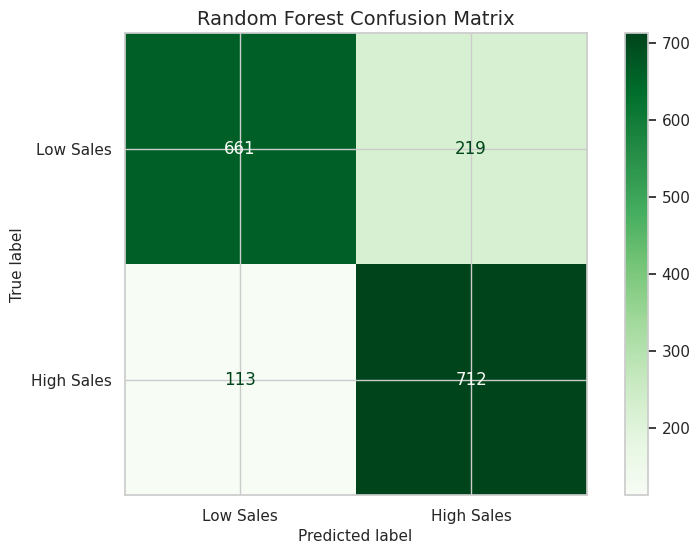

In [34]:
from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(
    y_test,
    rf_predictions
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Low Sales", "High Sales"]
)

disp.plot(cmap="Greens")

plt.title("Random Forest Confusion Matrix")

plt.show()

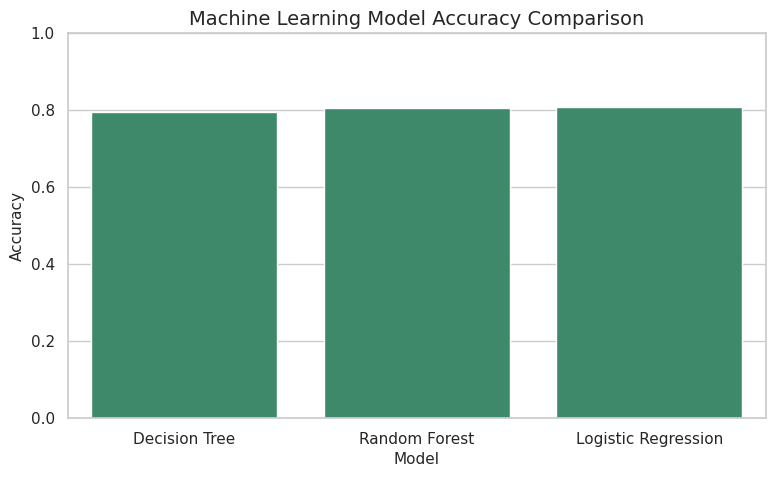

In [35]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=results_df,
    x="Model",
    y="Accuracy",
    color="#32956B"
)

plt.title("Machine Learning Model Accuracy Comparison")

plt.ylabel("Accuracy")
plt.xlabel("Model")

plt.ylim(0, 1)

plt.show()

In [36]:
best_model_name = results_df.loc[
    results_df["Accuracy"].idxmax(),
    "Model"
]

print("Best model:", best_model_name)

Best model: Logistic Regression


In [39]:
models = {
    "Decision Tree": decision_tree,
    "Random Forest": random_forest,
    "Logistic Regression": logistic_regression
}

best_model = models[best_model_name]

In [38]:
best_predictions = best_model.predict(X_test)

print(
    classification_report(
        y_test,
        best_predictions,
        target_names=["Low Sales", "High Sales"],
        zero_division=0
    )
)

              precision    recall  f1-score   support

   Low Sales       0.81      0.83      0.82       880
  High Sales       0.81      0.79      0.80       825

    accuracy                           0.81      1705
   macro avg       0.81      0.81      0.81      1705
weighted avg       0.81      0.81      0.81      1705



In [40]:
results_df.to_csv(
    "Model_Comparison.csv",
    index=False
)

In [41]:
best_accuracy = accuracy_score(
    y_test,
    best_predictions
)

model_summary = pd.DataFrame({
    "Best_Model": [best_model_name],
    "Accuracy": [best_accuracy],
    "Accuracy_Percentage": [
        round(best_accuracy * 100, 2)
    ],
    "Precision": [
        precision_score(
            y_test,
            best_predictions,
            zero_division=0
        )
    ],
    "Recall": [
        recall_score(
            y_test,
            best_predictions,
            zero_division=0
        )
    ],
    "F1_Score": [
        f1_score(
            y_test,
            best_predictions,
            zero_division=0
        )
    ]
})

display(model_summary)

model_summary.to_csv(
    "Best_Model_Metrics.csv",
    index=False
)

,Best_Model,Accuracy,Accuracy_Percentage,Precision,Recall,F1_Score
0,Logistic Regression,0.809384,80.94,0.810174,0.791515,0.800736


In [42]:
from google.colab import files

files.download("Model_Comparison.csv")

files.download("Best_Model_Metrics.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>